In [ ]:
import numpy as np
import matplotlib.pyplot as plt



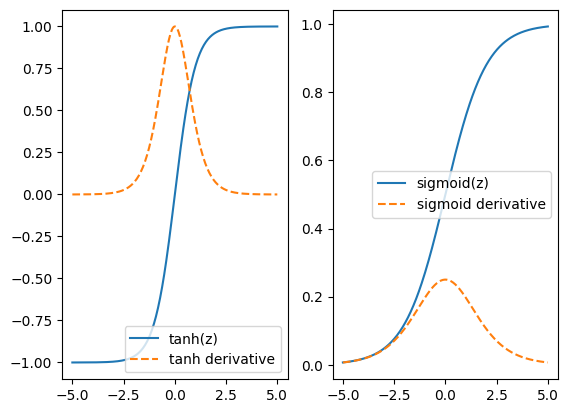

In [ ]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

z = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2)
axes[0].plot(z, np.tanh(z), label="tanh(z)")
axes[0].plot(z, 1 - np.tanh(z) ** 2, "--", label="tanh derivative")
axes[0].legend()

s = sigmoid(z)
axes[1].plot(z, s, label="sigmoid(z)")
axes[1].plot(z, s * (1 - s), "--", label="sigmoid derivative")
axes[1].legend()

plt.show()


In [ ]:
X_one = np.array([[1.0, 0.5]])
y_one = np.array([[1.0]])

params_one = {
    "W1": np.array([[0.4, -0.2],
                    [0.1, 0.3]]),
    "b1":np.array([[0.0, 0.0]]),
    "W2": np.array([[0.7],
                    [-0.5]]),
    "b2": np.array([[0.0]])
}

print(f"X_one shape{X_one.shape}\n{X_one}")
for name, value in params_one.items():
    print(f"{name}: shape={value.shape}\n{value}")

X_one shape(1, 2)
[[1.  0.5]]
W1: shape=(2, 2)
[[ 0.4 -0.2]
 [ 0.1  0.3]]
b1: shape=(1, 2)
[[0. 0.]]
W2: shape=(2, 1)
[[ 0.7]
 [-0.5]]
b2: shape=(1, 1)
[[0.]]


In [ ]:
def forward(X, params):
    Z1 = X @ params["W1"] + params["b1"] # 1 x 2 @ 2 x 2 = 1 x 2
    A1 = np.tanh(Z1) # 1 x 2

    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = sigmoid(Z2)

    cache = {"Z1":Z1, "A1":A1, "Z2":Z2, "A2":A2}
    return A2, cache

A2_one, cache_one = forward(X_one, params_one)
for name, value in cache_one.items():
    print(f"{name}:shape={value.shape}, value={value}")


Z1:shape=(1, 2), value=[[ 0.45 -0.05]]
A1:shape=(1, 2), value=[[ 0.42189901 -0.04995837]]
Z2:shape=(1, 1), value=[[0.32030849]]
A2:shape=(1, 1), value=[[0.57939943]]


In [ ]:
def binary_cross_entropy(Y, A2):
    eps = 1e-12
    A2 = np.clip(A2, eps, 1-eps)
    return -np.mean(Y * np.log(A2) + (1-Y) * np.log(1 - A2))

In [ ]:
loss_one = binary_cross_entropy(y_one, A2_one)
print(f"Prediction:{A2_one}")
print(f"loss={loss_one}")

Prediction:[[0.57939943]]
loss=0.5457631740294328


In [ ]:
params_random = {
    "W1": np.random.randn(2, 2),
    "b1":np.array([[0.0, 0.0]]),
    "W2": np.random.randn(2, 2),
    "b2": np.array([[0.0]])
}
print(params_random)
A2_random, cache_random = forward(X_one, params_random)
binary_cross_entropy(y_one, A2_random)

{'W1': array([[-1.74832899, -0.83746182],
       [-0.35851998,  1.54913885]]), 'b1': array([[0., 0.]]), 'W2': array([[-1.01275821, -0.89962978],
       [ 0.46298319, -0.13116131]]), 'b2': array([[0.]])}


np.float64(0.3395161477790227)

In [ ]:
def backward(X, Y, params, cache):
    m = X.shape[0]
    A1, A2 = cache["A1"], cache["A2"]

    # output layer
    dZ2 = (A2 - Y) / m # 1x1
    dW2 = A1.T @ dZ2 # 2x1
    db2 = np.sum((dZ2), axis=0, keepdims=True)

    # Hidden layer
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (1 - A1 ** 2)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return {
        "dZ2":dZ2, "dW2":dW2, "db2":db2,
        "dA1":dA1, "dZ1":dZ1, "dW1":dW1, "db1":db1
    }


In [ ]:
grads_one = backward(X_one, y_one, params_one, cache_one)
for name, value in grads_one.items():
    print(f"{name}: shape={value.shape}\n{value}")

dZ2: shape=(1, 1)
[[-0.42060057]]
dW2: shape=(2, 1)
[[-0.17745096]
 [ 0.02101252]]
db2: shape=(1, 1)
[[-0.42060057]]
dA1: shape=(1, 2)
[[-0.2944204   0.21030028]]
dZ1: shape=(1, 2)
[[-0.24201393  0.20977541]]
dW1: shape=(2, 2)
[[-0.24201393  0.20977541]
 [-0.12100696  0.1048877 ]]
db1: shape=(1, 2)
[[-0.24201393  0.20977541]]


In [ ]:
def update(params, grads, learning_rate):
    params['W1'] -= learning_rate * grads['dW1']
    params['W2'] -= learning_rate * grads['dW2']
    params['b1'] -= learning_rate * grads['db1']
    params['b2'] -= learning_rate * grads['db2']
    return params



In [ ]:
updated_one = {name:value.copy() for name, value in params_one.items()}
print(f"before update: prob={A2_one.item()}, loss={loss_one}")

before update: prob=0.5793994319666315, loss=0.5457631740294328


In [ ]:
for i in range(50):
    updated_one = update(updated_one, grads_one, learning_rate=0.1)

    new_prediction, _ = forward(X_one, updated_one)
    new_loss = binary_cross_entropy(y_one, new_prediction)

    print(f"after update: prob={new_prediction.item()}, loss={new_loss}")

after update: prob=0.6046555901066167, loss=0.5030962555994822
after update: prob=0.6293524466592623, loss=0.46306385065503625
after update: prob=0.6533168534262258, loss=0.4256930400914366
after update: prob=0.6764023635896281, loss=0.3909671675971286
after update: prob=0.6984918506995434, loss=0.3588317672113844
after update: prob=0.7194982410908054, loss=0.3292011972847973
after update: prob=0.7393635932685245, loss=0.30196547190049544
after update: prob=0.7580568727885371, loss=0.2769968660903468
after update: prob=0.7755708204181002, loss=0.25415597826811415
after update: prob=0.7919183038210068, loss=0.23329704422937095
after update: prob=0.8071284946948973, loss=0.21427239823859512
after update: prob=0.8212431420636046, loss=0.19693605982566628
after update: prob=0.8343131340962715, loss=0.18114648654397536
after update: prob=0.8463954670353814, loss=0.16676857347445964
after update: prob=0.8575506775798633, loss=0.15367500246983265
after update: prob=0.8678407473558979, loss=0.

In [ ]:
rng = np.random.default_rng(7)
n_samples = 500

X = rng.uniform(-1, 1, size=(n_samples, 2))
X += rng.normal(0, 0.08, size=X.shape)
Y = ((X[:, 0] * X[:, 1]) < 0).astype(float).reshape(-1, 1)

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, stratify=Y, test_size=0.2)



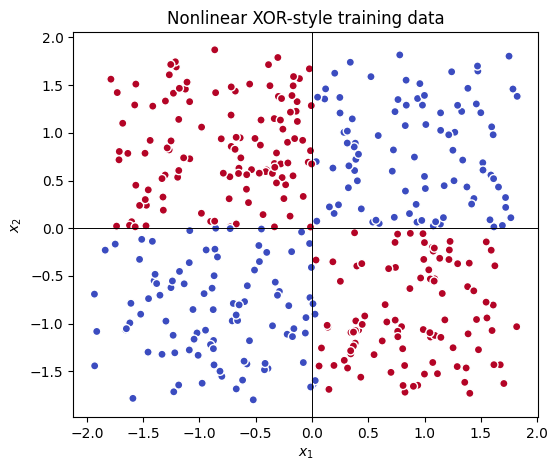

X_train: (400, 2) Y_train: (400, 1)
X_test:  (100, 2) Y_test:  (100, 1)


In [ ]:
# Fit standardization on training data only
mean = X_train.mean(axis=0, keepdims=True)
std = X_train.std(axis=0, keepdims=True)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

plt.figure(figsize=(6, 5))
plt.scatter(X_train[:, 0], X_train[:, 1],
            c=Y_train.ravel(), cmap="coolwarm", edgecolor="white", s=35)
plt.axhline(0, color="black", linewidth=0.7)
plt.axvline(0, color="black", linewidth=0.7)
plt.title("Nonlinear XOR-style training data")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_test: ", X_test.shape,  "Y_test: ", Y_test.shape)

In [ ]:
# 2, 4, 1 -> three layers, input = 2 neurons, 1 hidden layer = 4 neurons, output = 1 neuron
def initilaize_parameters(n_features, n_hidden, seed=42):
    rng = np.random.default_rng(seed)
    return {
        "W1":np.random.randn(n_features, n_hidden),
        "b1":np.zeros((1, n_hidden)),
        "W2":np.random.randn(n_hidden, 1),
        "b2":np.zeros((1, 1))
    }
params = initilaize_parameters(2, 4)
for name, value in params.items():
    print(name,value.shape)

W1 (2, 4)
b1 (1, 4)
W2 (4, 1)
b2 (1, 1)


In [ ]:
def train(X, Y, n_hidden=4, learning_rate=0.5, epochs=500):
    params = initilaize_parameters(X.shape[1], n_hidden)
    loss_history = []

    for epoch in range(epochs+1):
        predictions, cache = forward(X, params)
        loss = binary_cross_entropy(Y, predictions)
        grads = backward(X, Y, params, cache)
        params = update(params, grads, learning_rate)

        if epoch % 20 == 0:
            loss_history.append((epoch, loss))
    return params, np.array(loss_history)




Last loss value 0.0639639431897764


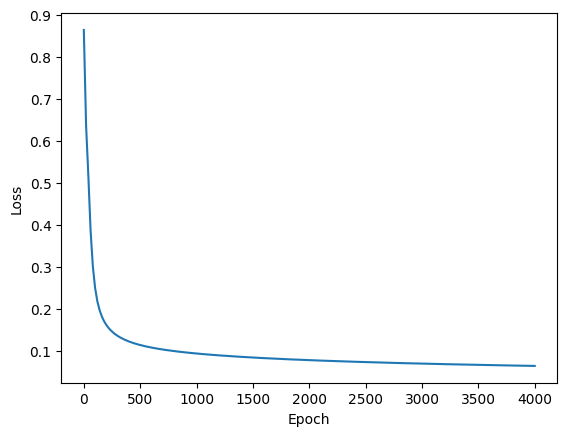

In [ ]:
trained_params, history = train(X_train, Y_train, epochs=4000)
print("Last loss value", history[:, 1][-1])
plt.plot(history[:, 0], history[:, 1])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
def predict(X, params, threshold=0.5):
    probs, _ = forward(X, params)
    return (probs >= threshold).astype(int)

In [ ]:
train_accuracy = np.mean(predict(X_train, trained_params) == Y_train)
test_accuracy = np.mean(predict(X_test, trained_params) == Y_test)

print(f"{train_accuracy=}, {test_accuracy=}")

train_accuracy=np.float64(0.99), test_accuracy=np.float64(0.95)


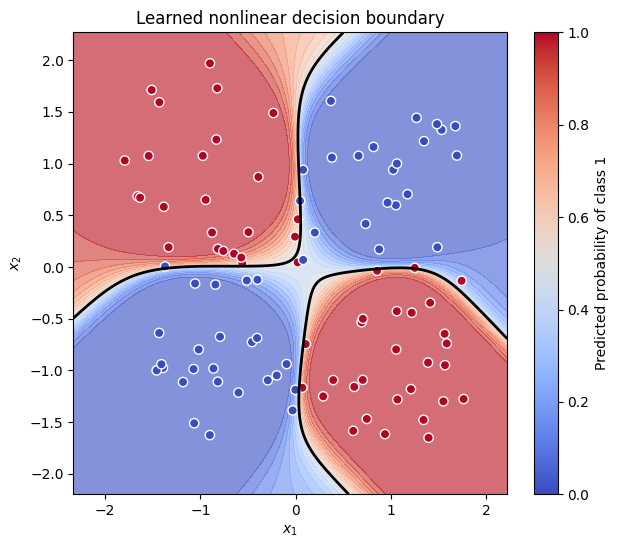

In [ ]:
def predict_proba(X, params):
    probabilities, _ = forward(X, params)
    return probabilities

x1_min, x1_max = X_train[:, 0].min() - 0.4, X_train[:, 0].max() + 0.4
x2_min, x2_max = X_train[:, 1].min() - 0.4, X_train[:, 1].max() + 0.4

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 300),
    np.linspace(x2_min, x2_max, 300)
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_probability = predict_proba(grid, trained_params).reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, grid_probability,
             levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.65)
plt.contour(xx, yy, grid_probability,
            levels=[0.5], colors="black", linewidths=2)
plt.scatter(X_test[:, 0], X_test[:, 1],
            c=Y_test.ravel(), cmap="coolwarm",
            edgecolor="white", s=45)
plt.colorbar(label="Predicted probability of class 1")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Learned nonlinear decision boundary")
plt.show()

In [ ]:
from sklearn.neural_network import MLPClassifier

sklearn_mlp = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation="tanh",
    solver="sgd",
    alpha=0.0,
    batch_size=len(X_train),
    learning_rate='constant',
    learning_rate_init=0.5,
    momentum=0.0,
    nesterovs_momentum=False,
    max_iter=4000,
    tol=1e-5,
    n_iter_no_change=100,
    random_state=42
)


In [ ]:
sklearn_mlp.fit(X_train, Y_train)


print(f"Training accuracy: {sklearn_mlp.score(X_train, Y_train.ravel()):.3f}")
print(f"Test accuracy:     {sklearn_mlp.score(X_test, Y_test.ravel()):.3f}")
print(f"Iterations:        {sklearn_mlp.n_iter_}")
print("Weight shapes:    ", [w.shape for w in sklearn_mlp.coefs_])
print("Bias shapes:      ", [b.shape for b in sklearn_mlp.intercepts_])

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1124: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Training accuracy: 0.988
Test accuracy:     0.950
Iterations:        2189
Weight shapes:     [(2, 4), (4, 1)]
Bias shapes:       [(4,), (1,)]


In [ ]:
trained_params

{'W1': array([[ 1.55497217, -1.66017799, -1.9353982 , -2.40173624],
        [-1.75668489, -1.73053622, -2.00265711,  2.29386013]]),
 'b1': array([[ 1.79966609, -1.77278004,  2.10389326,  2.44330397]]),
 'W2': array([[-9.16127651],
        [-7.96551721],
        [ 8.61468878],
        [-7.22267591]]),
 'b2': array([[-0.27287776]])}

In [ ]:
sklearn_mlp.coefs_

[array([[-2.00722078,  1.59184591, -1.74306394, -2.39528852],
        [-2.0338134 , -1.77003193, -1.80068805,  2.30727194]]),
 array([[ 6.94226984],
        [-7.33349809],
        [-6.33432202],
        [-5.89726873]])]

In [ ]:
sklearn_mlp.intercepts_

[array([ 2.19555562,  1.7929712 , -1.8393817 ,  2.45304443]),
 array([-0.28485901])]

In [ ]:
our_probabilities, _ = forward(X_test, trained_params)
sklearn_probabilities = sklearn_mlp.predict_proba(X_test)[:, 1].reshape(-1, 1)

max_difference = np.max(np.abs(our_probabilities - sklearn_probabilities))

In [ ]:
max_difference

np.float64(0.1042844358492418)